### CREDIT CARD FRAUD DETECTION
Code By Siddhartha Mettu

### 1. IMPORT LIBRARIES

In [10]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import SMOTE

### 2. LOAD DATA

In [13]:
df = pd.read_csv(r"C:\Users\Siddhartha Mettu\OneDrive\Desktop\Internship\Credit card\fraudTrain.csv")

### 3. PRE PREPROCESSING

In [16]:
# Convert transaction datetime
df['trans_date_trans_time'] = pd.to_datetime(
    df['trans_date_trans_time'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

# Drop invalid rows
df = df.dropna(subset=['trans_date_trans_time'])

# Extract features
df['hour'] = df['trans_date_trans_time'].dt.hour
df['day'] = df['trans_date_trans_time'].dt.day
df['month'] = df['trans_date_trans_time'].dt.month

# Convert DOB safely
df['dob'] = pd.to_datetime(
    df['dob'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

# Age
df['age'] = 2020 - df['dob'].dt.year

# Drop unnecessary columns safely
drop_cols = [
    'index', 'trans_date_trans_time', 'cc_num', 'first', 'last',
    'street', 'city', 'state', 'zip', 'trans_num', 'dob'
]

df = df.drop(columns=[col for col in drop_cols if col in df.columns])

### 4. ENCODE CATEGORICAL FEATURES

In [17]:
cat_cols = ['merchant', 'category', 'gender', 'job']

le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

### 5. EXPLORATORY DATA ANALYSIS

##### CLASS DISTRIBUTION

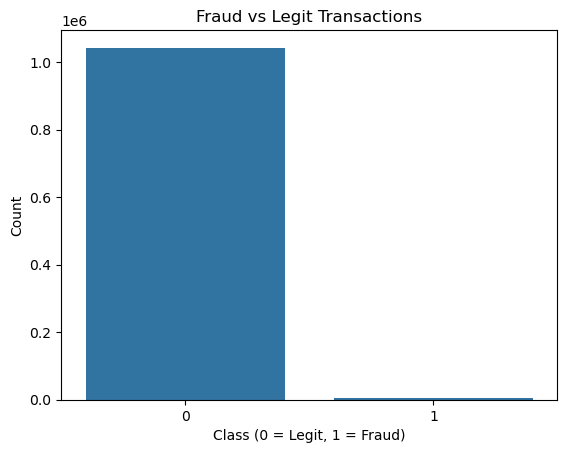

is_fraud
0    0.994272
1    0.005728
Name: proportion, dtype: float64


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure()
sns.countplot(x='is_fraud', data=df)
plt.title("Fraud vs Legit Transactions")
plt.xlabel("Class (0 = Legit, 1 = Fraud)")
plt.ylabel("Count")
plt.show()

print(df['is_fraud'].value_counts(normalize=True))

##### TRANSACTION AMOUNT ANALYSIS

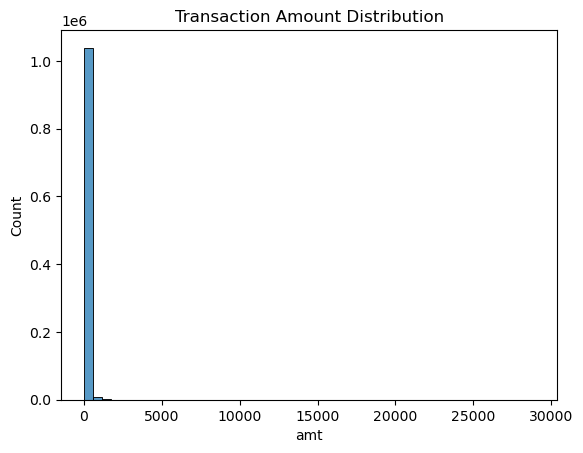

In [23]:
plt.figure()
sns.histplot(df['amt'], bins=50)
plt.title("Transaction Amount Distribution")
plt.show()

##### Fraud vs Amount

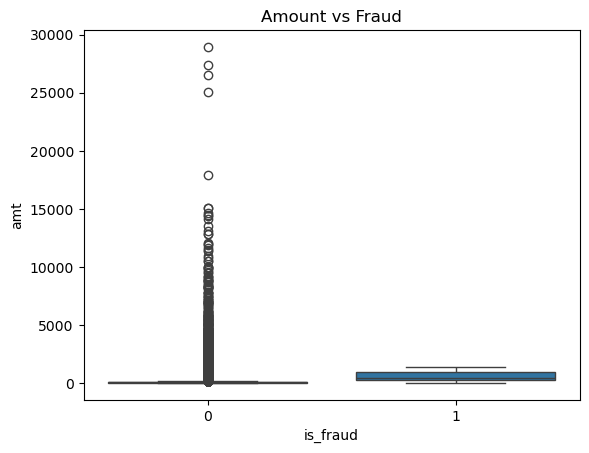

In [36]:
plt.figure()
sns.boxplot(x='is_fraud', y='amt', data=df)
plt.title("Amount vs Fraud")
plt.show()

##### TIME-BASED ANALYSIS

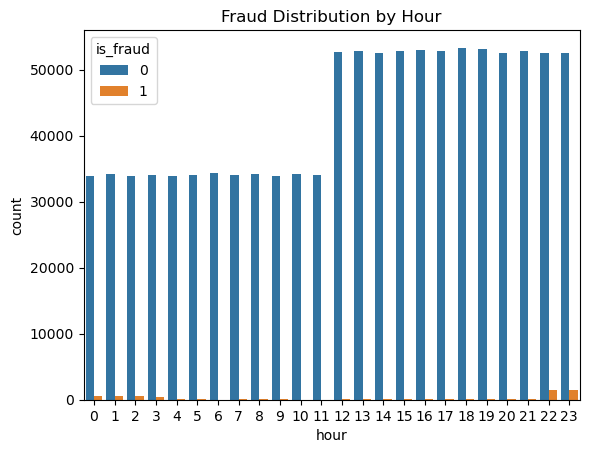

In [24]:
plt.figure()
sns.countplot(x='hour', hue='is_fraud', data=df)
plt.title("Fraud Distribution by Hour")
plt.show()

##### CATEGORY vs FRAUD

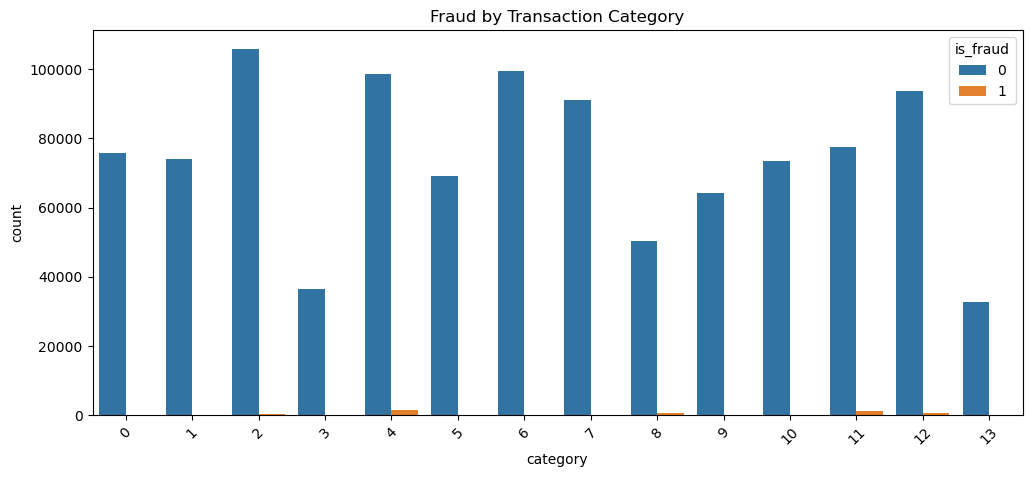

In [25]:
plt.figure(figsize=(12,5))
sns.countplot(x='category', hue='is_fraud', data=df)
plt.xticks(rotation=45)
plt.title("Fraud by Transaction Category")
plt.show()

##### GENDER vs FRAUD

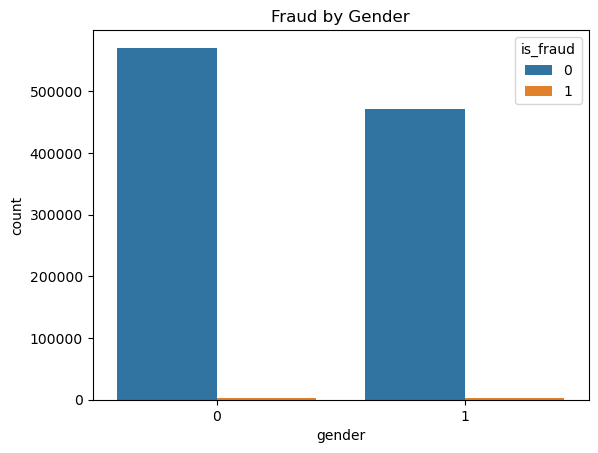

In [26]:
plt.figure()
sns.countplot(x='gender', hue='is_fraud', data=df)
plt.title("Fraud by Gender")
plt.show()

##### CORRELATION HEATMAP

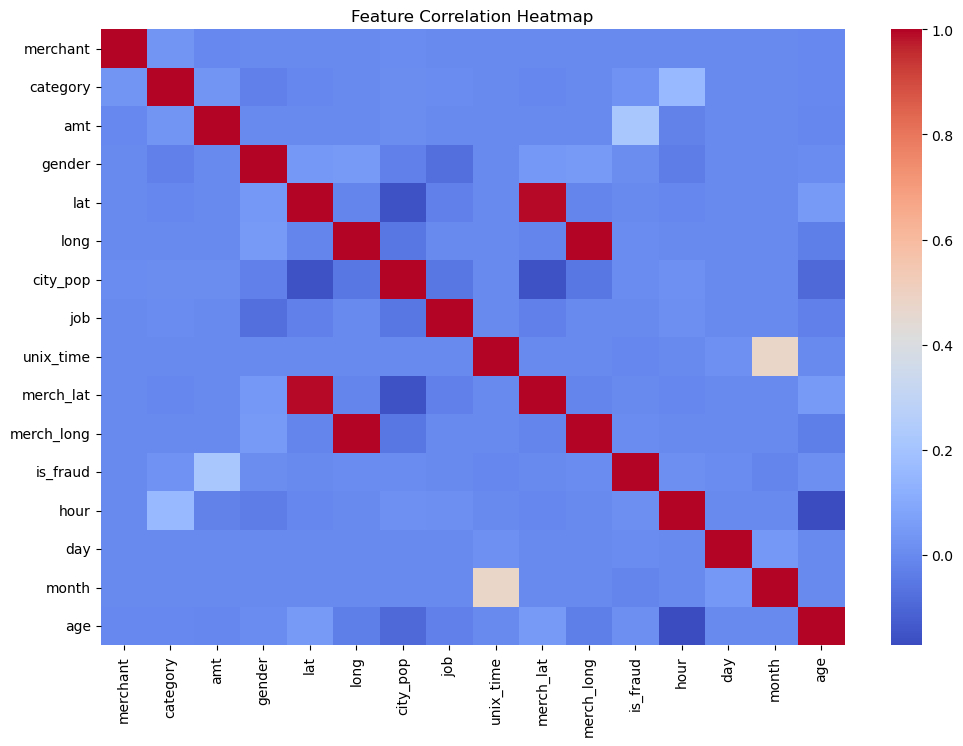

In [27]:
plt.figure(figsize=(12,8))
corr = df.corr(numeric_only=True)

sns.heatmap(corr, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

##### LOCATION DISTANCE

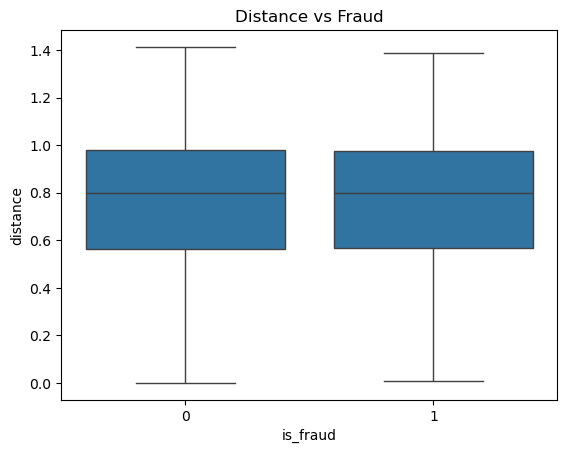

In [28]:
import numpy as np

df['distance'] = np.sqrt(
    (df['lat'] - df['merch_lat'])**2 +
    (df['long'] - df['merch_long'])**2
)

plt.figure()
sns.boxplot(x='is_fraud', y='distance', data=df)
plt.title("Distance vs Fraud")
plt.show()

##### Age Distribution vs Fraud

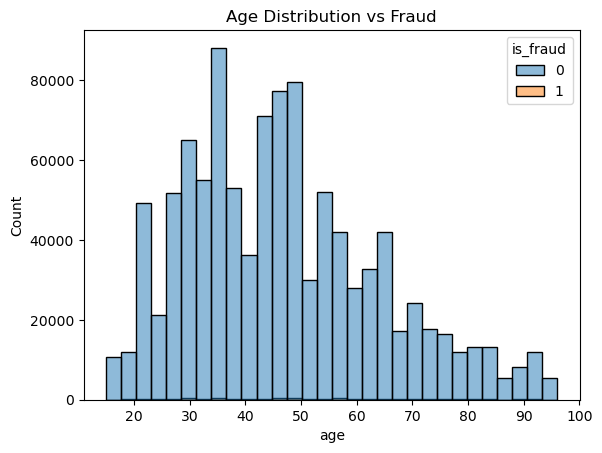

In [29]:
plt.figure()
sns.histplot(data=df, x='age', hue='is_fraud', bins=30)
plt.title("Age Distribution vs Fraud")
plt.show()

### 6. SPLIT DATA

In [18]:
X = df.drop('is_fraud', axis=1)
y = df['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### 7. HANDLE IMBALANCE (SMOTE)

In [19]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)


### 8. FEATURE SCALING

In [20]:
scaler = StandardScaler()
X_train_res = scaler.fit_transform(X_train_res)
X_test = scaler.transform(X_test)



### 9. MODELS

#####  Logistic Regression

In [30]:

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_res, y_train_res)


LogisticRegression(max_iter=1000)

#####  Decision Tree

In [31]:

dt = DecisionTreeClassifier(max_depth=10)
dt.fit(X_train_res, y_train_res)


DecisionTreeClassifier(max_depth=10)

##### Random Forest

In [32]:

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_res, y_train_res)


RandomForestClassifier(random_state=42)

###  10. EVALUATION

In [33]:

def evaluate(model, name):
    y_pred = model.predict(X_test)
    print(f"\n{name} Results:")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred))


In [34]:
evaluate(lr, "Logistic Regression")
evaluate(dt, "Decision Tree")
evaluate(rf, "Random Forest")


Logistic Regression Results:
[[196956  11558]
 [   296    905]]
              precision    recall  f1-score   support

           0       1.00      0.94      0.97    208514
           1       0.07      0.75      0.13      1201

    accuracy                           0.94    209715
   macro avg       0.54      0.85      0.55    209715
weighted avg       0.99      0.94      0.97    209715


Decision Tree Results:
[[200376   8138]
 [   139   1062]]
              precision    recall  f1-score   support

           0       1.00      0.96      0.98    208514
           1       0.12      0.88      0.20      1201

    accuracy                           0.96    209715
   macro avg       0.56      0.92      0.59    209715
weighted avg       0.99      0.96      0.98    209715


Random Forest Results:
[[207949    565]
 [   250    951]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    208514
           1       0.63      0.79      0.70      1201


### Manual Fraud Prediction

##### TEST WITH CUSTOM DATA

In [35]:

sample = X.iloc[0:1].copy()  # take one sample

# Modify values (simulate suspicious transaction)
sample['amt'] = 5000  # high amount
sample['hour'] = 2    # odd time

# Scale it
sample_scaled = scaler.transform(sample)

# Predict
prediction = rf.predict(sample_scaled)
prob = rf.predict_proba(sample_scaled)

print("Prediction:", "FRAUD" if prediction[0] == 1 else "LEGIT")
print("Fraud Probability:", prob[0][1])

Prediction: LEGIT
Fraud Probability: 0.15
